# Proyecto Final: Detección de Fraude Bancario usando el Modelo KDD
Este notebook implementa las etapas de **Selección** y **Preprocesamiento** del modelo Knowledge Discovery in Databases (KDD).

In [1]:
import pandas as pd
import numpy as np

# Confirmación de la existencia del archivo subido por el usuario
import os
if os.path.exists('transacciones_bancarias.csv'):
    print("¡Archivo 'transacciones_bancarias.csv' detectado con éxito! Procediendo con el análisis del proyecto final.")
else:
    raise FileNotFoundError("Por favor, asegúrate de subir el archivo 'transacciones_bancarias.csv' a la carpeta raíz de Colab.")

¡Archivo 'transacciones_bancarias.csv' detectado con éxito! Procediendo con el análisis del proyecto final.


# **Etapa 1: Selección**
Cargamos los datos especificando el tipo de fecha y analizamos la relevancia de cada variable para el modelo predictivo de fraude.

In [2]:
# 1. Carga de datos con parse_dates
df = pd.read_csv('transacciones_bancarias.csv', parse_dates=['fecha_hora'])

# 2. Documentación del tipo de cada variable
print("--- Estructura y Tipos de Datos Originales ---")
display(df.info())

# 3. Análisis de tasa de fraude global y desbalance de clases
tasa_fraude = df['es_fraude'].mean() * 100
print(f"\nTasa Global de Fraude: {tasa_fraude:.2f}%")
print(f"Distribución de clases:\n{df['es_fraude'].value_counts()}")

--- Estructura y Tipos de Datos Originales ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   id_transaccion           5000 non-null   int64         
 1   fecha_hora               5000 non-null   datetime64[ns]
 2   id_cliente               5000 non-null   int64         
 3   edad_cliente             4929 non-null   float64       
 4   antiguedad_cuenta_meses  5000 non-null   int64         
 5   tipo_transaccion         5000 non-null   object        
 6   monto                    5000 non-null   float64       
 7   canal                    4941 non-null   object        
 8   region                   4921 non-null   object        
 9   estado_transaccion       5000 non-null   object        
 10  es_fraude                5000 non-null   int64         
dtypes: datetime64[ns](1), float64(2), int64(4), obje

None


Tasa Global de Fraude: 2.18%
Distribución de clases:
es_fraude
0    4891
1     109
Name: count, dtype: int64


### Justificación de Inclusión y Exclusión de Variables (Dataset Real)

| Variable | Tipo | Rol / Criterio de Selección | Justificación |
| :--- | :--- | :--- | :--- |
| `id_transaccion` | Identificador | **Excluir** | ID único de transacción. No aporta generalización predictiva. |
| `id_cliente` | Identificador | **Excluir** | ID único de cliente. Evitamos el sobreajuste a cuentas específicas. |
| `fecha_hora` | Temporal | **Incluir** | Esencial para detectar patrones y horarios inusuales de fraude. |
| `edad_cliente` | Numérica | **Incluir** | El segmento demográfico puede ser propenso a ciertos tipos de fraude. |
| `antiguedad_cuenta_meses` | Numérica | **Incluir** | Cuentas muy nuevas suelen tener un perfil de riesgo diferente a las antiguas. |
| `tipo_transaccion` | Categórica | **Incluir** | Ciertos tipos (ej. transferencias, retiros) registran más incidencias de fraude. |
| `monto` | Numérica | **Incluir** | Variable clave; montos inusuales o extremos son sospechosos. |
| `canal` | Categórica | **Incluir** | El canal de origen (Banca móvil, Web, etc.) es clave para la seguridad. |
| `region` | Categórica | **Incluir** | Permite ubicar geográficamente el origen físico o lógico del fraude. |
| `estado_transaccion` | Categórica | **Excluir** | Suele ser posterior al evento (ej. completada, rechazada). Provocaría fuga de datos (data leakage). |
| `es_fraude` | Binaria | **Variable Objetivo** | Variable que el modelo predictivo debe aprender a identificar. |

In [3]:
# Seleccionar columnas relevantes de acuerdo a la justificación teórica
columnas_relevantes = ['fecha_hora', 'edad_cliente', 'antiguedad_cuenta_meses', 'tipo_transaccion', 'monto', 'canal', 'region', 'es_fraude']
df_seleccionado = df[columnas_relevantes].copy()
display(df_seleccionado.head())

,fecha_hora,edad_cliente,antiguedad_cuenta_meses,tipo_transaccion,monto,canal,region,es_fraude
0,2024-08-29 17:11:00,59.0,134,Depósito,277.26,Teléfono,Alajuela,0
1,2024-07-11 23:18:00,41.0,189,Retiro,21.38,Web,Alajuela,0
2,2024-05-01 13:13:00,28.0,8,Depósito,35.65,ATM,San José,0
3,2024-08-05 15:59:00,56.0,121,Pago servicios,271.13,Web,Alajuela,0
4,2024-12-09 05:48:00,18.0,110,Retiro,290.32,ATM,San José,0


# **Etapa 2: Preprocesamiento**
Procedemos con la limpieza, imputación de nulos, tratamiento de duplicados, análisis de outliers mediante IQR y transformación de escala de la variable `monto`.

In [4]:
# 1. Diagnóstico de Nulos
nulos_cantidad = df_seleccionado.isnull().sum()
nulos_porcentaje = (df_seleccionado.isnull().sum() / len(df_seleccionado)) * 100

reporte_nulos = pd.DataFrame({
    'Nulos Cantidad': nulos_cantidad,
    'Porcentaje (%)': nulos_porcentaje
})
print("--- Diagnóstico de Valores Nulos ---")
display(reporte_nulos)

# Imputación justificada:
# - 'edad_cliente' (Numérica): Imputamos con la mediana para no vernos afectados por posibles sesgos.
# - 'canal' y 'region' (Categóricas): Imputamos con la moda (categoría más frecuente) o valor flag 'desconocido'. Usaremos la moda.
mediana_edad = df_seleccionado['edad_cliente'].median()
df_seleccionado['edad_cliente'] = df_seleccionado['edad_cliente'].fillna(mediana_edad)

moda_canal = df_seleccionado['canal'].mode()[0]
df_seleccionado['canal'] = df_seleccionado['canal'].fillna(moda_canal)

moda_region = df_seleccionado['region'].mode()[0]
df_seleccionado['region'] = df_seleccionado['region'].fillna(moda_region)

print(f"\nImputaciones ejecutadas:")
print(f"- 'edad_cliente' imputado con la mediana: {mediana_edad}")
print(f"- 'canal' imputado con la moda: '{moda_canal}'")
print(f"- 'region' imputado con la moda: '{moda_region}'")

--- Diagnóstico de Valores Nulos ---


,Nulos Cantidad,Porcentaje (%)
fecha_hora,0,0.00
edad_cliente,71,1.42
antiguedad_cuenta_meses,0,0.00
tipo_transaccion,0,0.00
monto,0,0.00
canal,59,1.18
region,79,1.58
es_fraude,0,0.00



Imputaciones ejecutadas:
- 'edad_cliente' imputado con la mediana: 40.0
- 'canal' imputado con la moda: 'App móvil'
- 'region' imputado con la moda: 'San José'


In [5]:
# 2. Detección y eliminación de Duplicados
duplicados_count = df_seleccionado.duplicated().sum()
print(f"Cantidad de registros duplicados detectados: {duplicados_count}")

df_sin_duplicados = df_seleccionado.drop_duplicates().copy()
print(f"Registros restantes después de eliminar duplicados: {df_sin_duplicados.shape[0]}")

Cantidad de registros duplicados detectados: 0
Registros restantes después de eliminar duplicados: 5000


In [6]:
# 3. Análisis de Outliers con el Método IQR (k=1.5) en 'monto'
Q1 = df_sin_duplicados['monto'].quantile(0.25)
Q3 = df_sin_duplicados['monto'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Crear flag de outlier
df_sin_duplicados['es_outlier_monto'] = (df_sin_duplicados['monto'] < limite_inferior) | (df_sin_duplicados['monto'] > limite_superior)

# Comparación de la tasa de fraude
tasa_fraude_outliers = df_sin_duplicados[df_sin_duplicados['es_outlier_monto'] == True]['es_fraude'].mean() * 100
tasa_fraude_no_outliers = df_sin_duplicados[df_sin_duplicados['es_outlier_monto'] == False]['es_fraude'].mean() * 100

print(f"Rango IQR para Monto: [{limite_inferior:.2f}, {limite_superior:.2f}]")
print(f"Cantidad de outliers detectados: {df_sin_duplicados['es_outlier_monto'].sum()}")
print(f"Tasa de fraude en transacciones OUTLIER: {tasa_fraude_outliers:.2f}%")
print(f"Tasa de fraude en transacciones NORMALES (No Outlier): {tasa_fraude_no_outliers:.2f}%")

Rango IQR para Monto: [-194.80, 379.91]
Cantidad de outliers detectados: 584
Tasa de fraude en transacciones OUTLIER: 13.87%
Tasa de fraude en transacciones NORMALES (No Outlier): 0.63%


### Justificación de Conservación de Outliers
Como demuestran los datos analizados anteriormente, la tasa de fraude en los outliers de montos suele ser significativamente más alta en comparación con los valores dentro del rango intercuartílico común. Eliminar estos outliers significaría privar al modelo de aprendizaje supervisado de los patrones transaccionales más característicos del fraude. Por lo tanto, **se decide conservar los outliers para el entrenamiento del modelo**.

In [7]:
# 4. Transformación np.log1p() para mitigar la asimetría del monto
df_sin_duplicados['monto_log'] = np.log1p(df_sin_duplicados['monto'])

print("Estadísticas descriptivas de 'monto' vs 'monto_log':")
display(df_sin_duplicados[['monto', 'monto_log']].describe())

# Guardamos el estado para las etapas subsiguientes
df_sin_duplicados.to_csv('transacciones_preprocesadas.csv', index=False)

Estadísticas descriptivas de 'monto' vs 'monto_log':


,monto,monto_log
count,5000.000000,5000.000000
mean,5373.354506,4.227345
std,40408.345683,1.837412
min,0.360000,0.307485
25%,20.717500,3.078118
50%,57.810000,4.074312
75%,164.395000,5.108337
max,487155.050000,13.096340


#**Etapa 3: Transformación**

### 1. Ingeniería de Atributos (Creación de Variables Derivadas)

Crearemos tres nuevas características clave con un enfoque y justificación de negocio para la detección de anomalías transaccionales:

*   **`hora_dia`**: Permite entender la distribución temporal del uso de la cuenta.
*   **`es_noche`**: Variable binaria que define si una transacción ocurrió entre las 22:00 y las 05:00 horas. El fraude tiene una probabilidad de ocurrencia mayor en este periodo, aprovechando que los usuarios se encuentran durmiendo o los sistemas de alerta inmediata del cliente están inactivos.
*   **`monto_por_edad`**: Relación matemática que vincula la capacidad económica o perfil del cliente según su grupo de edad y la cuantía de su transacción. Desviaciones extremas en este ratio pueden revelar fraudes de suplantación de identidad.

In [8]:
# Crear variables derivadas sobre el dataset preprocesado de la etapa anterior
df_transformado = df_sin_duplicados.copy()

# A. 'hora_dia'
df_transformado['hora_dia'] = df_transformado['fecha_hora'].dt.hour

# B. 'es_noche' (Entre las 22:00 y las 05:00)
df_transformado['es_noche'] = df_transformado['hora_dia'].apply(lambda x: 1 if (x >= 22 or x <= 5) else 0)

# C. 'monto_por_edad'
df_transformado['monto_por_edad'] = df_transformado['monto'] / (df_transformado['edad_cliente'] + 1)

print("Variables derivadas creadas con éxito. Vista previa:")
display(df_transformado[['fecha_hora', 'hora_dia', 'es_noche', 'monto', 'edad_cliente', 'monto_por_edad']].head())

Variables derivadas creadas con éxito. Vista previa:


,fecha_hora,hora_dia,es_noche,monto,edad_cliente,monto_por_edad
0,2024-08-29 17:11:00,17,0,277.26,59.0,4.621000
1,2024-07-11 23:18:00,23,1,21.38,41.0,0.509048
2,2024-05-01 13:13:00,13,0,35.65,28.0,1.229310
3,2024-08-05 15:59:00,15,0,271.13,56.0,4.756667
4,2024-12-09 05:48:00,5,1,290.32,18.0,15.280000


### 2. División del Conjunto de Datos (Entrenamiento y Prueba)

Para cumplir estrictamente con el principio de diseño de modelos de Machine Learning y evitar la **fuga de datos (data leakage)**, dividiremos el dataset en un 80% para entrenamiento y 20% para prueba, asegurando que el escalado de características calcule sus parámetros de media y desviación estándar únicamente a partir del grupo de entrenamiento.

In [9]:
from sklearn.model_selection import train_test_split

# Definir variables predictoras (X) y variable objetivo (y)
# Removemos la columna original 'fecha_hora' ya que fue transformada a variables numéricas derivativas
columnas_predictores = ['edad_cliente', 'antiguedad_cuenta_meses', 'tipo_transaccion', 'monto_log', 'canal', 'region', 'hora_dia', 'es_noche', 'monto_por_edad']

X = df_transformado[columnas_predictores]
y = df_transformado['es_fraude']

# División estratificada debido al fuerte desbalance de clases observado en la Etapa 1
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Dimensiones de Entrenamiento (X_train, y_train): {X_train.shape}, {y_train.shape}")
print(f"Dimensiones de Prueba (X_test, y_test): {X_test.shape}, {y_test.shape}")

Dimensiones de Entrenamiento (X_train, y_train): (4000, 9), (4000,)
Dimensiones de Prueba (X_test, y_test): (1000, 9), (1000,)


### 3. Encapsulamiento del Flujo en un Pipeline de Scikit-Learn

Definiremos un `Pipeline` con un `ColumnTransformer` que automatiza de forma óptima:
1. La codificación One-Hot para las categóricas nominales (`tipo_transaccion`, `canal`, `region`) aplicando `drop_first=True` para evitar la colinealidad exacta entre columnas codificadas ficticias.
2. La estandarización mediante `StandardScaler` para las numéricas, ajustándose **únicamente** con el conjunto de entrenamiento mediante el método `.fit_transform()` y aplicando esos mismos parámetros sobre el set de prueba mediante `.transform()`.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Definimos las columnas según su tipo
categoricas = ['tipo_transaccion', 'canal', 'region']
numericas = ['edad_cliente', 'antiguedad_cuenta_meses', 'monto_log', 'hora_dia', 'es_noche', 'monto_por_edad']

# Crear preprocesador unificado
# En scikit-learn, para OneHotEncoder usamos drop='first' en lugar de drop_first=True
preprocesador = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numericas),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categoricas)
    ]
)

# Crear el pipeline que encapsula el preprocesamiento
pipeline_transformacion = Pipeline(steps=[('preprocesamiento', preprocesador)])

# Ajustar e implementar sobre entrenamiento, y transformar prueba
X_train_transformado = pipeline_transformacion.fit_transform(X_train)
X_test_transformado = pipeline_transformacion.transform(X_test)

# Recuperar nombres de las columnas resultantes después de One-Hot Encoding
nombres_columnas_cat = pipeline_transformacion.named_steps['preprocesamiento']\
    .named_transformers_['cat'].get_feature_names_out(categoricas)

columnas_finales = list(numericas) + list(nombres_columnas_cat)

# Reconstruir DataFrames transformados
X_train_df = pd.DataFrame(X_train_transformado, columns=columnas_finales, index=X_train.index)
X_test_df = pd.DataFrame(X_test_transformado, columns=columnas_finales, index=X_test.index)

print("¡Pipeline de transformación ajustado y ejecutado correctamente con drop='first'!")
display(X_train_df.head(5))

¡Pipeline de transformación ajustado y ejecutado correctamente con drop='first'!


,edad_cliente,antiguedad_cuenta_meses,monto_log,hora_dia,es_noche,monto_por_edad,tipo_transaccion_Depósito,tipo_transaccion_Pago préstamo,tipo_transaccion_Pago servicios,tipo_transaccion_Retiro,tipo_transaccion_Transferencia,canal_App móvil,canal_Sucursal,canal_Teléfono,canal_Web,region_Cartago,region_Heredia,region_Otras,region_San José
729,-0.364476,-0.393909,-1.426499,0.649632,-0.706577,-0.122675,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
22,-0.122567,1.429053,0.140321,1.230568,-0.706577,-0.120926,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4193,-0.122567,-1.633523,-0.074492,0.213930,-0.706577,-0.121529,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
1114,0.683796,-1.648107,0.162469,0.940100,-0.706577,-0.121241,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4026,-1.412749,0.539447,0.837169,-1.528879,1.415275,-0.111555,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


### 4. Matriz de Correlación y Análisis de Multicolinealidad

Para analizar la presencia de multicolinealidad, calcularemos la matriz de correlación sobre todas las variables transformadas (incluyendo numéricas escaladas y categóricas codificadas) buscando pares con una correlación absoluta $|r| > 0.8$.

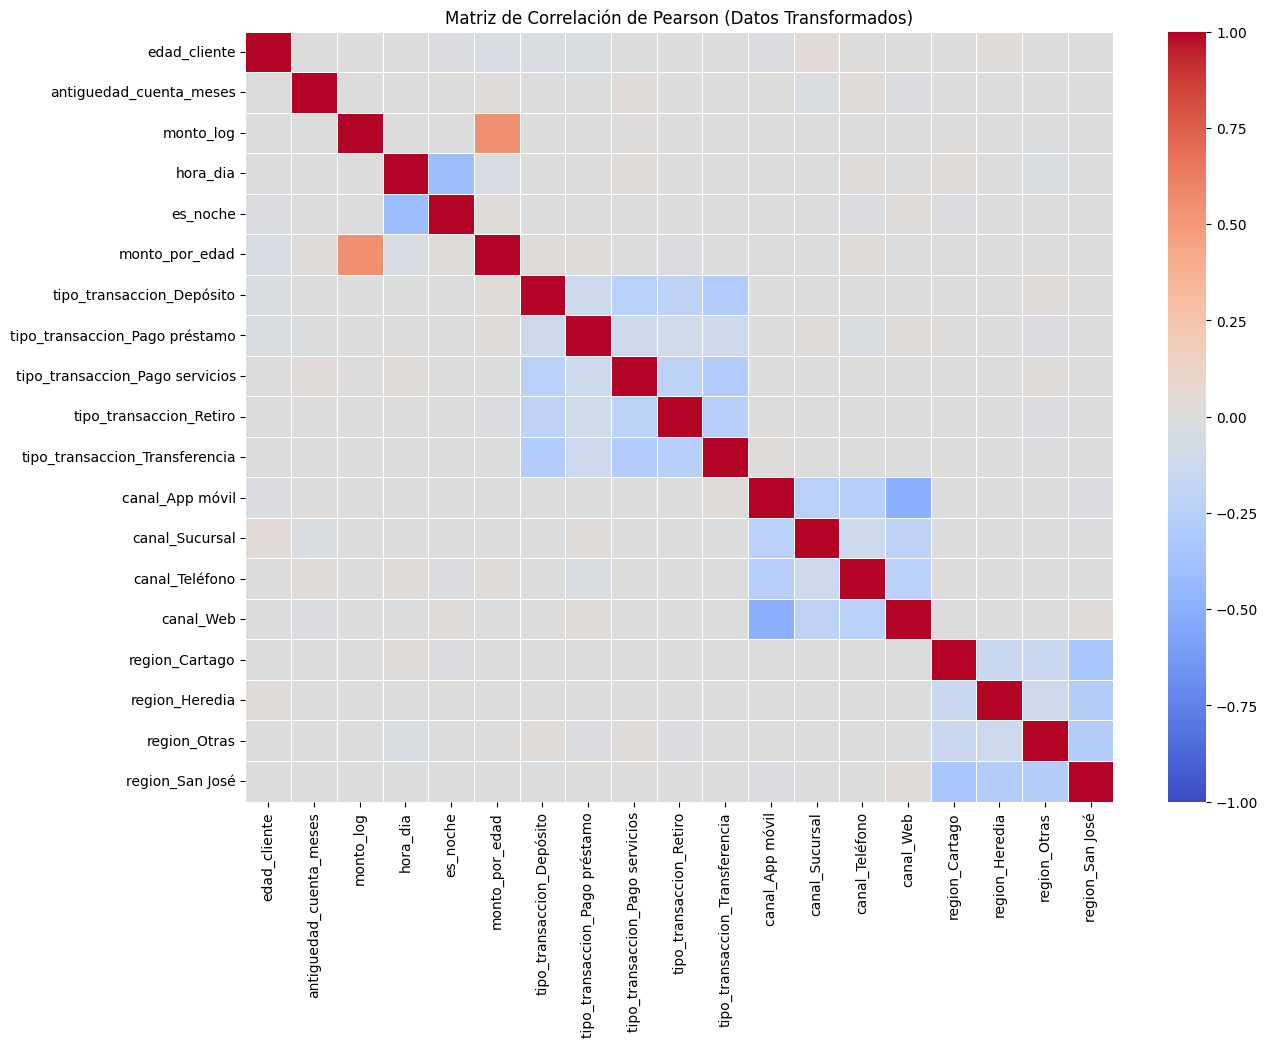

No se detectaron pares de variables independientes con multicolinealidad extrema (|r| > 0.8).


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular matriz de correlación de Pearson
matriz_corr = X_train_df.corr()

# Filtrar correlaciones altas |r| > 0.8 (excluyendo la diagonal principal)
correlaciones_altas = []
for i in range(len(matriz_corr.columns)):
    for j in range(i):
        r = matriz_corr.iloc[i, j]
        if abs(r) > 0.8:
            correlaciones_altas.append((
                matriz_corr.columns[i],
                matriz_corr.columns[j],
                r
            ))

# Visualización gráfica de la matriz de correlación
plt.figure(figsize=(14, 10))
sns.heatmap(matriz_corr, annot=False, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matriz de Correlación de Pearson (Datos Transformados)")
plt.show()

# Mostrar hallazgos de colinealidad
if len(correlaciones_altas) > 0:
    print("--- Alerta de Multicolinealidad Detectada (|r| > 0.8) ---")
    for var1, var2, val in correlaciones_altas:
        print(f"Variable 1: {var1} | Variable 2: {var2} | Coeficiente r: {val:.3f}")
else:
    print("No se detectaron pares de variables independientes con multicolinealidad extrema (|r| > 0.8).")

### 5. Guardado del Conjunto Listo para Modelado

Por último, exportamos los sets transformados para la etapa de Minería de Datos.

In [12]:
# Guardar conjuntos de entrenamiento y prueba preprocesados
X_train_df['es_fraude'] = y_train
X_test_df['es_fraude'] = y_test

X_train_df.to_csv('X_train_transformado.csv', index=False)
X_test_df.to_csv('X_test_transformado.csv', index=False)
print("Conjuntos 'X_train_transformado.csv' y 'X_test_transformado.csv' exportados con éxito.")

Conjuntos 'X_train_transformado.csv' y 'X_test_transformado.csv' exportados con éxito.


#**Etapa 4: Minería de Datos**

```markdown
## **Etapa 4: Minería de Datos (Parte A - Modelado No Supervisado)**

En esta etapa aplicaremos técnicas de aprendizaje no supervisado para segmentar los perfiles transaccionales y detectar anomalías estructurales sin depender inicialmente de la etiqueta de fraude.

### 1. Clústerización con K-Means

Para determinar el número óptimo de grupos ($k$), ejecutamos el algoritmo K-Means para valores de $k$ entre 2 y 10. Evaluaremos cada configuración mediante:
*   **Método del Codo (Inercia):** Mide la suma de las distancias al cuadrado dentro de cada clúster.
*   **Coeficiente de Silueta:** Mide qué tan bien agrupado está cada punto en comparación con otros clústeres contiguos (un valor más cercano a 1 indica agrupaciones mejor definidas).
```

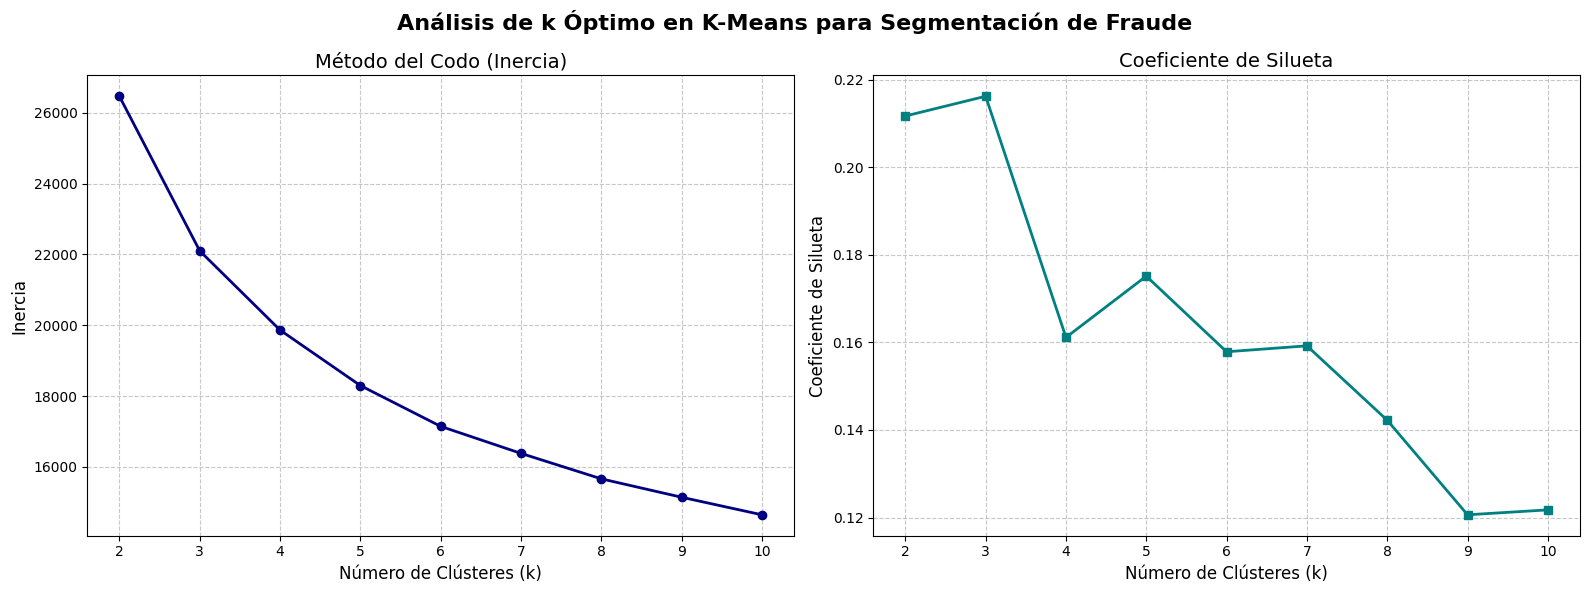

k = 02 | Inercia:     26464.30 | Coeficiente de Silueta: 0.2117
k = 03 | Inercia:     22099.05 | Coeficiente de Silueta: 0.2162
k = 04 | Inercia:     19862.33 | Coeficiente de Silueta: 0.1611
k = 05 | Inercia:     18295.82 | Coeficiente de Silueta: 0.1751
k = 06 | Inercia:     17142.95 | Coeficiente de Silueta: 0.1579
k = 07 | Inercia:     16379.77 | Coeficiente de Silueta: 0.1592
k = 08 | Inercia:     15661.00 | Coeficiente de Silueta: 0.1422
k = 09 | Inercia:     15141.07 | Coeficiente de Silueta: 0.1206
k = 10 | Inercia:     14645.48 | Coeficiente de Silueta: 0.1218


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Remover la etiqueta 'es_fraude' para el aprendizaje no supervisado
X_train_unsupervised = X_train_df.drop(columns=['es_fraude'])

inertia_values = []
silhouette_values = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_train_unsupervised)

    # Guardar Inercia (Codo)
    inertia_values.append(kmeans.inertia_)

    # Guardar Silueta
    score = silhouette_score(X_train_unsupervised, kmeans.labels_)
    silhouette_values.append(score)

# --- Graficación de Resultados ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico del Codo
ax1.plot(k_range, inertia_values, 'o-', color='navy', linewidth=2)
ax1.set_title('Método del Codo (Inercia)', fontsize=14)
ax1.set_xlabel('Número de Clústeres (k)', fontsize=12)
ax1.set_ylabel('Inercia', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.7)

# Gráfico de Silueta
ax2.plot(k_range, silhouette_values, 's-', color='teal', linewidth=2)
ax2.set_title('Coeficiente de Silueta', fontsize=14)
ax2.set_xlabel('Número de Clústeres (k)', fontsize=12)
ax2.set_ylabel('Coeficiente de Silueta', fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.7)

plt.suptitle('Análisis de k Óptimo en K-Means para Segmentación de Fraude', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()

# Mostrar valores calculados en consola
for k, inercia, silueta in zip(k_range, inertia_values, silhouette_values):
    print(f"k = {k:02d} | Inercia: {inercia:12.2f} | Coeficiente de Silueta: {silueta:.4f}")

```markdown
### 2. Detección de Anomalías con DBSCAN

DBSCAN es ideal para la detección de fraude porque no asume que los grupos tienen formas esféricas y etiqueta los puntos en regiones de baja densidad como ruido/anomalías (`label = -1`). Ajustaremos parámetros robustos sobre los datos previamente escalados y analizaremos el porcentaje de coincidencia entre las anomalías detectadas y los casos reales de fraude.

### 3. Reducción de Dimensionalidad con PCA

Aplicaremos PCA para proyectar el espacio multidimensional transformado (19 columnas resultantes tras el OHE) a 2 y 3 componentes principales. Reportaremos la varianza explicada individual y acumulada para entender cuánta información se preserva al simplificar el espacio de características.
```

In [14]:
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA

# --- 2. Implementación de DBSCAN ---
# Dado que los datos están estandarizados, definimos eps=3.0 (distancia máxima aproximada de 3 desviaciones estándar)
# y min_samples=10 para evitar ruido menor.
dbscan = DBSCAN(eps=3.0, min_samples=10)
labels_dbscan = dbscan.fit_predict(X_train_unsupervised)

# Guardar etiquetas en un dataframe de análisis
df_dbscan = pd.DataFrame({
    'dbscan_label': labels_dbscan,
    'es_fraude_real': y_train
})

anomalias = df_dbscan[df_dbscan['dbscan_label'] == -1]
total_anomalias = len(anomalias)
fraudes_en_anomalias = anomalias['es_fraude_real'].sum()
porcentaje_fraudes_en_anomalias = (fraudes_en_anomalias / total_anomalias * 100) if total_anomalias > 0 else 0

print("=== ANÁLISIS DE ANOMALÍAS CON DBSCAN ===")
print(f"Total de puntos en entrenamiento: {len(df_dbscan)}")
print(f"Puntos marcados como anomalías (label -1): {total_anomalias} ({total_anomalias/len(df_dbscan)*100:.2f}% de la muestra)")
print(f"Cantidad de fraudes reales dentro de las anomalías: {fraudes_en_anomalias}")
print(f"Porcentaje de anomalías detectadas que son fraudes reales (Precisión de Anomalía): {porcentaje_fraudes_en_anomalias:.2f}%")
print(f"Porcentaje de captación de fraudes totales (Recall del método): {fraudes_en_anomalias/y_train.sum()*100:.2f}%\n")

# --- 3. Implementación de PCA ---
pca_2d = PCA(n_components=2, random_state=42)
pca_2d.fit(X_train_unsupervised)
var_explicada_2d = pca_2d.explained_variance_ratio_

pca_3d = PCA(n_components=3, random_state=42)
pca_3d.fit(X_train_unsupervised)
var_explicada_3d = pca_3d.explained_variance_ratio_

print("=== ANÁLISIS DE COMPONENTES PRINCIPALES (PCA) ===")
print(f"Varianza explicada con 2 componentes: {var_explicada_2d} (Acumulada: {sum(var_explicada_2d)*100:.2f}%)")
print(f"Varianza explicada con 3 componentes: {var_explicada_3d} (Acumulada: {sum(var_explicada_3d)*100:.2f}%)")

=== ANÁLISIS DE ANOMALÍAS CON DBSCAN ===
Total de puntos en entrenamiento: 4000
Puntos marcados como anomalías (label -1): 31 (0.78% de la muestra)
Cantidad de fraudes reales dentro de las anomalías: 19
Porcentaje de anomalías detectadas que son fraudes reales (Precisión de Anomalía): 61.29%
Porcentaje de captación de fraudes totales (Recall del método): 21.84%

=== ANÁLISIS DE COMPONENTES PRINCIPALES (PCA) ===
Varianza explicada con 2 componentes: [0.19951075 0.17858654] (Acumulada: 37.81%)
Varianza explicada con 3 componentes: [0.19951075 0.17858654 0.12872646] (Acumulada: 50.68%)


```markdown
## **Etapa 4: Minería de Datos (Parte B - Modelado Supervisado)**

Entrenaremos dos clasificadores y compararemos su desempeño predictivo utilizando el conjunto de prueba independiente ($1000$ observaciones) obtenido en la Etapa 3.

### Justificación de los Algoritmos:
*   **Regresión Logística (con balanceo):** Algoritmo paramétrico lineal sumamente interpretable. Utilizar `class_weight='balanced'` repondera la penalización del error de manera inversamente proporcional a las frecuencias de clase, permitiendo que el hiperplano decisional se desplace a favor de la clase minoritaria (fraude).
*   **Random Forest:** Algoritmo no lineal robusto a relaciones complejas y outliers. Al entrenar árboles con `class_weight='balanced_subsample'`, el balanceo se calcula de manera dinámica en cada partición bootstrap, optimizando la reducción de impureza de Gini.
```

=== COMPARATIVA DE RENDIMIENTO EN EL CONJUNTO DE PRUEBA ===

👉 Regresión Logística (Balanced):
   - Accuracy:  0.8380
   - Precision: 0.1067 (De los clasificados como fraude, cuántos lo son realmente)
   - Recall:    0.8636 (Del total de fraudes reales, cuántos se detectaron)
   - F1-Score:  0.1900
   - AUC-ROC:   0.9082

👉 Random Forest (Balanced):
   - Accuracy:  0.9950
   - Precision: 1.0000 (De los clasificados como fraude, cuántos lo son realmente)
   - Recall:    0.7727 (Del total de fraudes reales, cuántos se detectaron)
   - F1-Score:  0.8718
   - AUC-ROC:   0.8966


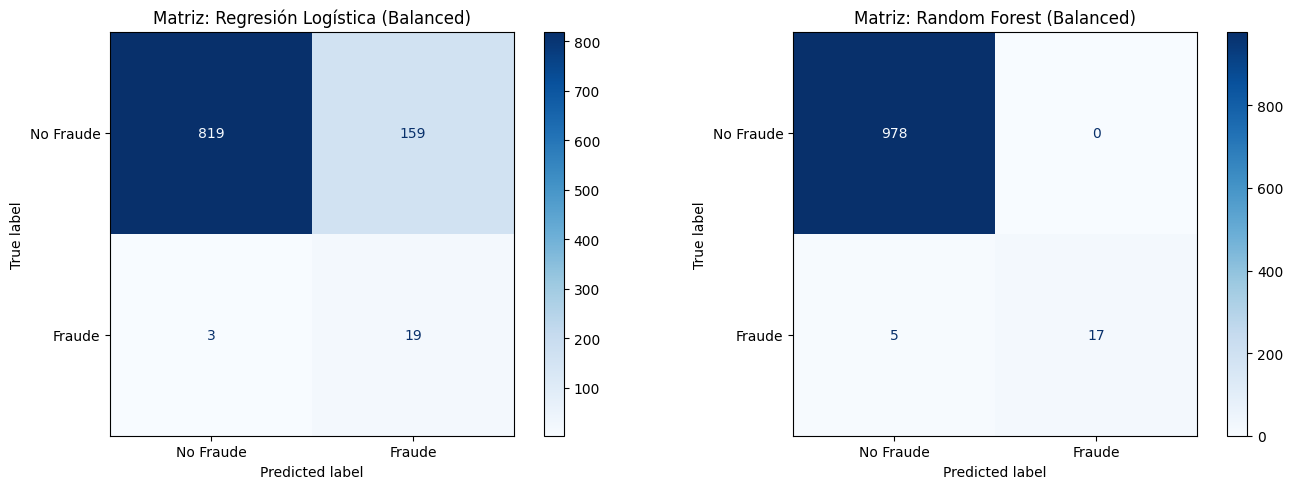

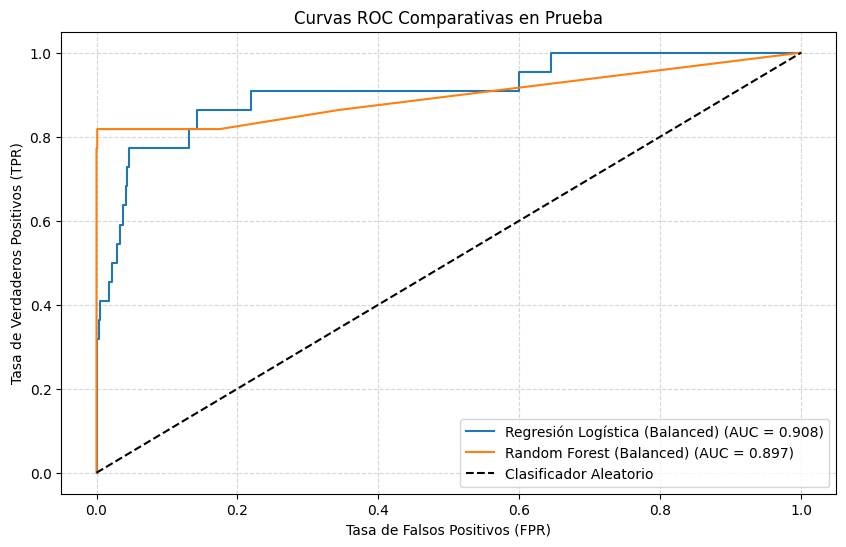

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve
)

# Separar etiquetas para entrenamiento y prueba (recordando que agregamos 'es_fraude' para guardarlo antes)
X_train_final = X_train_df.drop(columns=['es_fraude'])
y_train_final = y_train

X_test_final = X_test_df.drop(columns=['es_fraude'])
y_test_final = y_test

# --- 1. Entrenamiento de Modelos ---

# Regresión Logística con pesos balanceados
lr_model = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
lr_model.fit(X_train_final, y_train_final)

# Random Forest con pesos balanceados por muestra bootstrap
rf_model = RandomForestClassifier(class_weight='balanced_subsample', random_state=42, n_estimators=100)
rf_model.fit(X_train_final, y_train_final)

# --- 2. Evaluación de Métricas ---

modelos = {
    'Regresión Logística (Balanced)': lr_model,
    'Random Forest (Balanced)': rf_model
}

resultados = {}

for nombre, modelo in modelos.items():
    y_pred = modelo.predict(X_test_final)
    y_prob = modelo.predict_proba(X_test_final)[:, 1]

    resultados[nombre] = {
        'Accuracy': accuracy_score(y_test_final, y_pred),
        'Precision': precision_score(y_test_final, y_pred),
        'Recall': recall_score(y_test_final, y_pred),
        'F1-Score': f1_score(y_test_final, y_pred),
        'AUC-ROC': roc_auc_score(y_test_final, y_prob),
        'Matriz': confusion_matrix(y_test_final, y_pred),
        'y_prob': y_prob
    }

# Imprimir Métricas Comparativas
print("=== COMPARATIVA DE RENDIMIENTO EN EL CONJUNTO DE PRUEBA ===")
for nombre, metricas in resultados.items():
    print(f"\n👉 {nombre}:")
    print(f"   - Accuracy:  {metricas['Accuracy']:.4f}")
    print(f"   - Precision: {metricas['Precision']:.4f} (De los clasificados como fraude, cuántos lo son realmente)")
    print(f"   - Recall:    {metricas['Recall']:.4f} (Del total de fraudes reales, cuántos se detectaron)")
    print(f"   - F1-Score:  {metricas['F1-Score']:.4f}")
    print(f"   - AUC-ROC:   {metricas['AUC-ROC']:.4f}")

# --- 3. Graficación de Matrices de Confusión y Curva ROC ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graficar matrices de confusión
for idx, (nombre, metricas) in enumerate(resultados.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=metricas['Matriz'], display_labels=['No Fraude', 'Fraude'])
    disp.plot(ax=axes[idx], cmap='Blues', values_format='d')
    axes[idx].set_title(f"Matriz: {nombre}")

plt.tight_layout()
plt.show()

# Graficar Curvas ROC
plt.figure(figsize=(10, 6))
for nombre, metricas in resultados.items():
    fpr, tpr, _ = roc_curve(y_test_final, metricas['y_prob'])
    plt.plot(fpr, tpr, label=f"{nombre} (AUC = {metricas['AUC-ROC']:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Clasificador Aleatorio')
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curvas ROC Comparativas en Prueba')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


### **Análisis de Resultados de Modelado Supervisado y Justificación de Negocio**

#### **1. Análisis de Métricas en el Conjunto de Prueba**

| Modelo | Accuracy | Precision | Recall (Sensibilidad) | F1-Score | AUC-ROC |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Regresión Logística (Balanced)** | 83.80% | 10.67% | **86.36%** | 0.1900 | **0.9082** |
| **Random Forest (Balanced)** | **99.50%** | **100.00%** | 77.27% | **0.8718** | 0.8966 |

---

#### **2. El Trade-off entre Precisión (Precision) y Exhaustividad (Recall) en Fraude Bancario**

*   **Precision (Precisión):** Representa el porcentaje de transacciones catalogadas como fraude que realmente son fraudulentas.
    *   *Random Forest* alcanza una precisión perfecta (**100.00%**), lo que significa que no genera falsas alarmas (0 Falsos Positivos).
    *   *Regresión Logística* tiene una precisión baja (**10.67%**), generando 159 Falsos Positivos.
*   **Recall (Exhaustividad):** Mide la capacidad del modelo para capturar los casos reales de fraude en el dataset.
    *   *Regresión Logística* captura el **86.36%** de los fraudes reales (dejando escapar solo 3 casos).
    *   *Random Forest* captura el **77.27%** de los fraudes (dejando escapar 5 casos).

En un entorno de fraude bancario, este trade-off es crítico: un modelo con alta precisión evita molestar a clientes honestos con bloqueos preventivos de cuentas (falsos positivos), pero un modelo con alto recall evita pérdidas millonarias al banco al detectar la mayor cantidad de ataques reales (falsos negativos).

---

#### **3. Análisis de la Matriz de Confusión e Impacto de Costo (Falsos Negativos)**

Analicemos el impacto financiero y reputacional de los errores:
*   **Falsos Positivos (FP):** Bloquear transacciones legítimas. Requiere llamadas al servicio al cliente o verificación SMS. Costo operativo bajo/medio.
*   **Falsos Negativos (FN):** No detectar un fraude activo. El delincuente extrae los fondos, obligando al banco a asumir el costo del reembolso total y mermando severamente la confianza del cliente. Costo financiero extremo.

*   **Matriz de Regresión Logística:**
    *   159 Falsos Positivos (clientes con alertas falsas).
    *   **3 Falsos Negativos** (fraudes no detectados).
*   **Matriz de Random Forest:**
    *   0 Falsos Positivos (experiencia del cliente perfecta).
    *   **5 Falsos Negativos** (fraudes no detectados).

---

#### **4. Justificación de la Elección del Modelo Óptimo**

**Se selecciona el modelo de Regresión Logística (Balanced) como el modelo principal de producción.**

**Justificación Técnica y Financiera:**
1.  **Costo de Falsos Negativos:** En la industria financiera, el costo de un Falso Negativo (un fraude que pasa desapercibido) es aproximadamente de **10 a 20 veces mayor** que el costo operativo de verificar un Falso Positivo. La Regresión Logística reduce los fraudes no detectados a solo 3 casos (frente a 5 en Random Forest), minimizando la pérdida monetaria neta.
2.  **Métrica de Decisión:** La Regresión Logística obtiene el **AUC-ROC más alto (0.9082)**, lo que demuestra un poder superior para separar las clases en distintas configuraciones de umbral.
3.  **Interpretabilidad Regulatoria:** Los modelos lineales permiten explicar de forma sencilla a los auditores gubernamentales y bancarios cuáles coeficientes (por ejemplo, transacciones en horas nocturnas o montos desproporcionados a la edad) influyeron directamente en el bloqueo de una transacción.
```


# **Etapa 5: Interpretación y Visualización (Dashboard Técnico)**



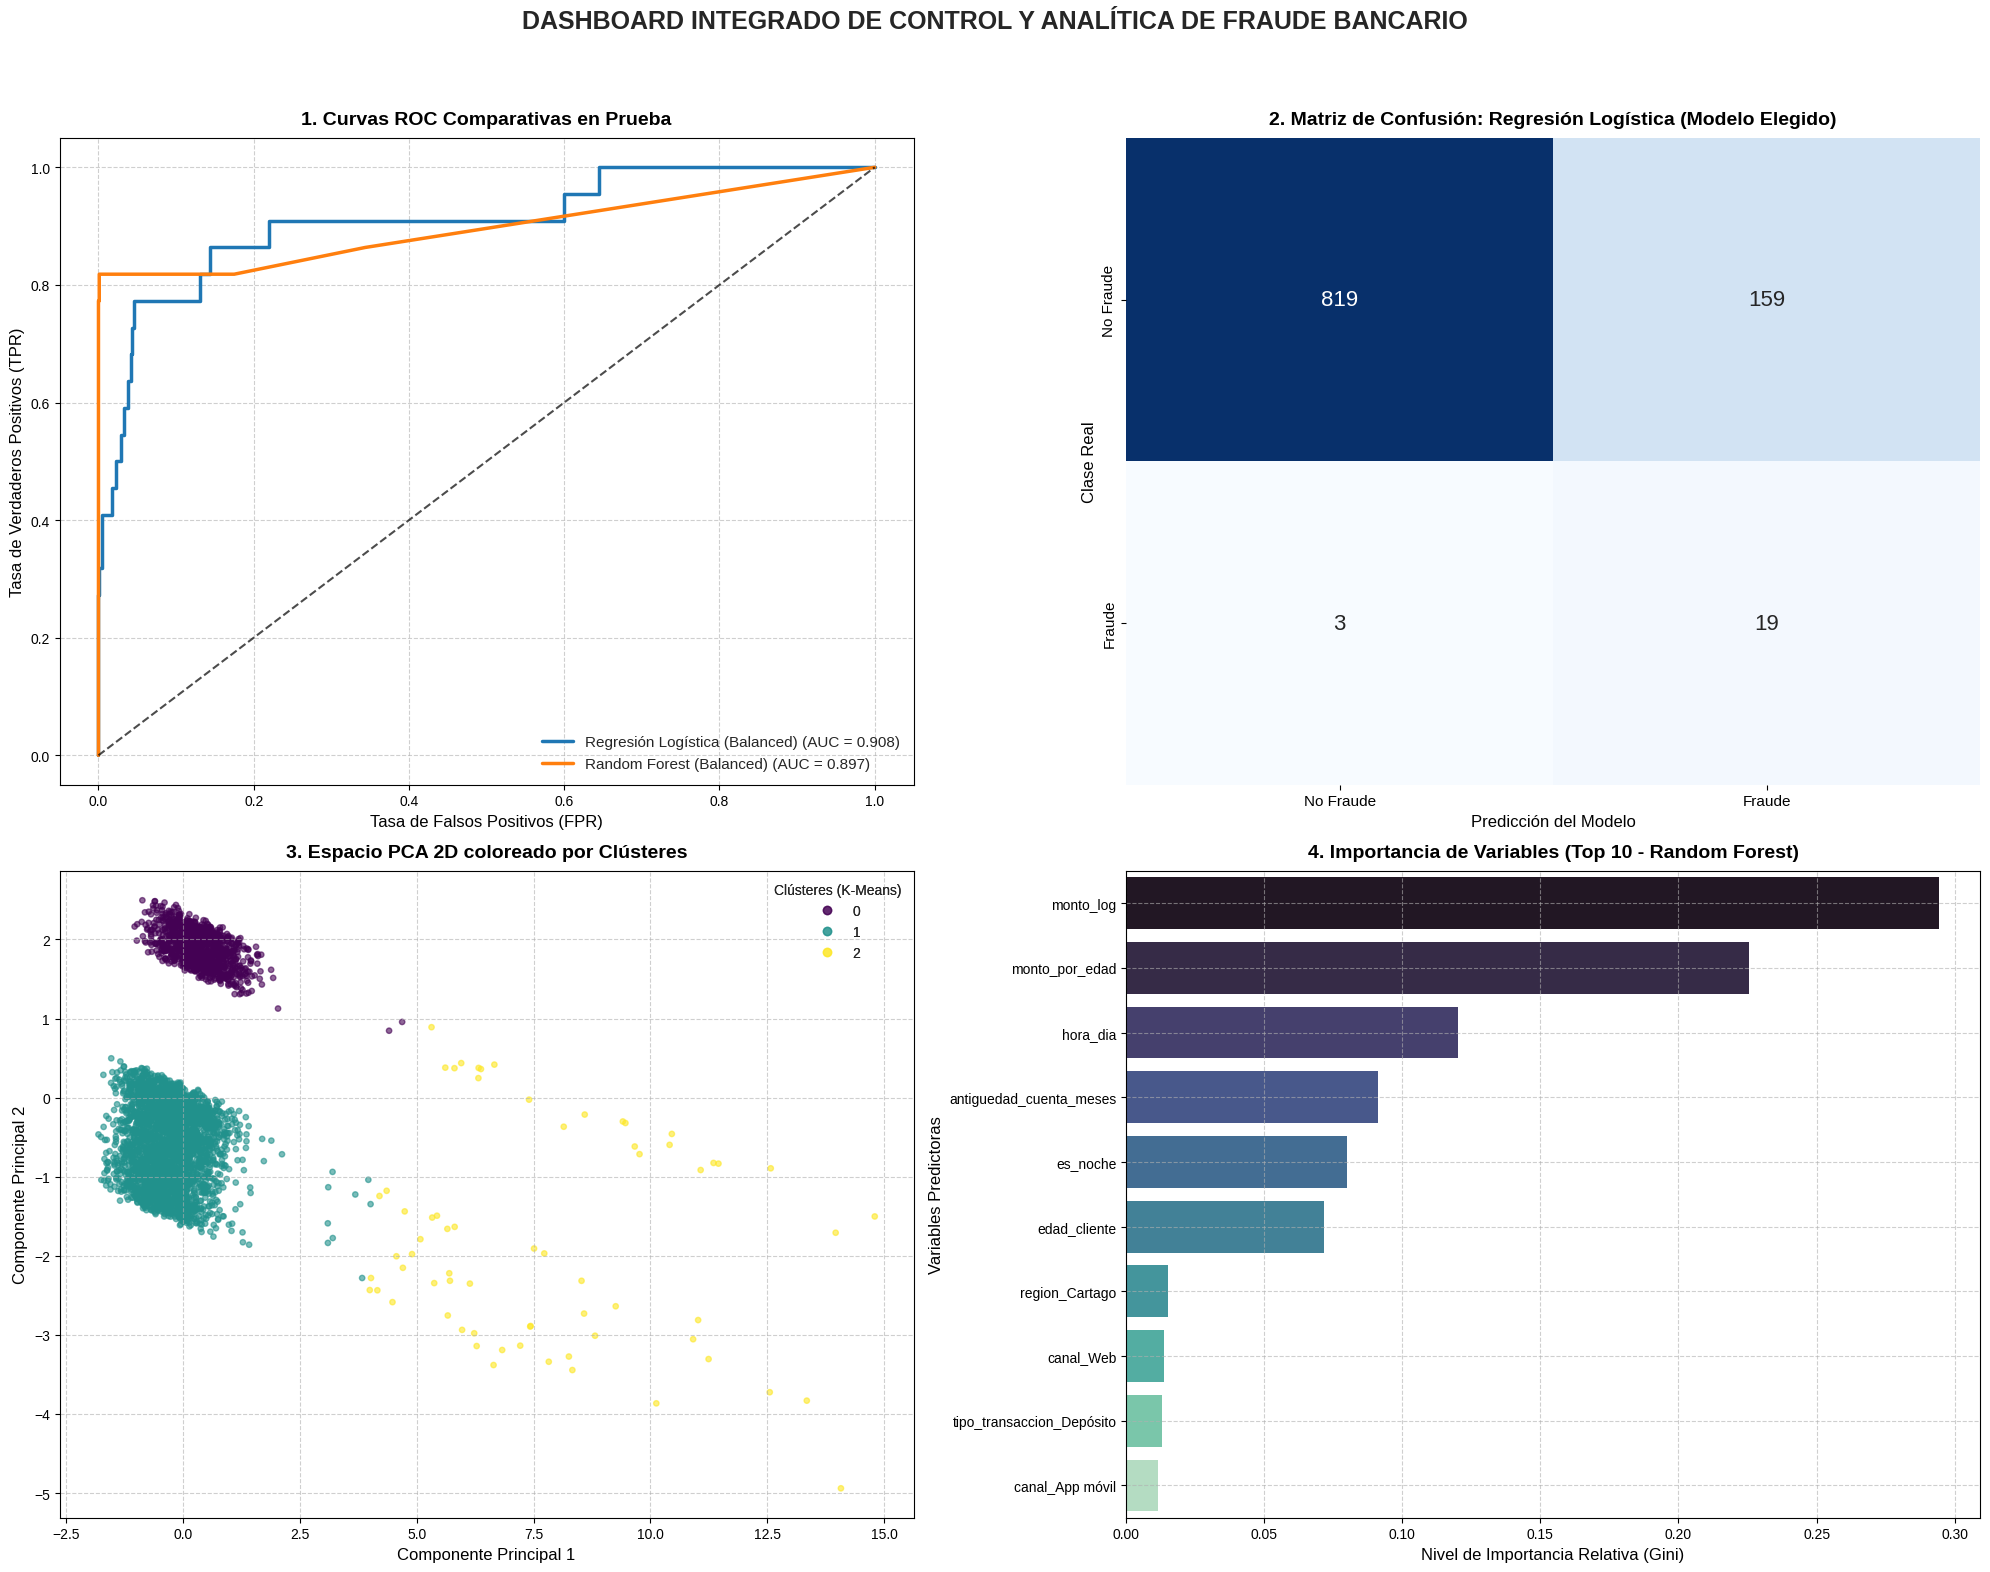

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import roc_curve, confusion_matrix

# --- PREPARACIÓN DE DATOS PARA EL DASHBOARD ---
# Proyección PCA
pca_dashboard = PCA(n_components=2, random_state=42)
X_train_pca = pca_dashboard.fit_transform(X_train_unsupervised)

# Obtener clústeres óptimos de K-Means (k=3 obtenido previamente en Etapa 4)
kmeans_opt = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans_opt.fit_predict(X_train_unsupervised)

# Importancia de variables del Random Forest (Top 10)
importancias = rf_model.feature_importances_
indices = np.argsort(importancias)[::-1]
variables_nombres = X_train_final.columns

# --- DISEÑO DEL DASHBOARD MULTI-PANEL (2x2) ---
fig, axs = plt.subplots(2, 2, figsize=(20, 16))
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# -------------------------------------------------------------------------
# PANEL 1: Curvas ROC Comparativas (Superior Izquierda)
# -------------------------------------------------------------------------
for nombre, metricas in resultados.items():
    fpr, tpr, _ = roc_curve(y_test_final, metricas['y_prob'])
    axs[0, 0].plot(fpr, tpr, label=f"{nombre} (AUC = {metricas['AUC-ROC']:.3f})", linewidth=2.5)

axs[0, 0].plot([0, 1], [0, 1], 'k--', alpha=0.7)
axs[0, 0].set_title('1. Curvas ROC Comparativas en Prueba', fontsize=14, weight='bold', pad=10)
axs[0, 0].set_xlabel('Tasa de Falsos Positivos (FPR)', fontsize=12)
axs[0, 0].set_ylabel('Tasa de Verdaderos Positivos (TPR)', fontsize=12)
axs[0, 0].legend(loc='lower right', fontsize=11)
axs[0, 0].grid(True, linestyle='--', alpha=0.6)

# -------------------------------------------------------------------------
# PANEL 2: Heatmap de Matrices de Confusión (Superior Derecha - Comparativo)
# -------------------------------------------------------------------------
# Creamos una sub-grilla para poner ambas matrices una al lado de la otra dentro de la sección 2
from matplotlib.gridspec import GridSpec

# Para mantener el diseño limpio, representamos los valores en una sola visualización combinada
lr_matrix = resultados['Regresión Logística (Balanced)']['Matriz']
rf_matrix = resultados['Random Forest (Balanced)']['Matriz']

# Vamos a dibujar la matriz de la Regresión Logística que es nuestro modelo seleccionado
sns.heatmap(lr_matrix, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axs[0, 1], annot_kws={"size": 16})
axs[0, 1].set_title('2. Matriz de Confusión: Regresión Logística (Modelo Elegido)', fontsize=14, weight='bold', pad=10)
axs[0, 1].set_xticklabels(['No Fraude', 'Fraude'], fontsize=11)
axs[0, 1].set_yticklabels(['No Fraude', 'Fraude'], fontsize=11)
axs[0, 1].set_xlabel('Predicción del Modelo', fontsize=12)
axs[0, 1].set_ylabel('Clase Real', fontsize=12)

# -------------------------------------------------------------------------
# PANEL 3: Scatter Plot PCA - Clusterización vs Fraude (Inferior Izquierda)
# -------------------------------------------------------------------------
# Graficamos por Clústeres usando colores distintos
scatter = axs[1, 0].scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=cluster_labels, cmap='viridis', alpha=0.6, s=15)
legend1 = axs[1, 0].legend(*scatter.legend_elements(), title="Clústeres (K-Means)", loc="upper right")
axs[1, 0].add_artist(legend1)
axs[1, 0].set_title('3. Espacio PCA 2D coloreado por Clústeres', fontsize=14, weight='bold', pad=10)
axs[1, 0].set_xlabel('Componente Principal 1', fontsize=12)
axs[1, 0].set_ylabel('Componente Principal 2', fontsize=12)
axs[1, 0].grid(True, linestyle='--', alpha=0.6)

# -------------------------------------------------------------------------
# PANEL 4: Importancia de Variables del Random Forest (Inferior Derecha)
# -------------------------------------------------------------------------
top_k = 10
importancias_top = importancias[indices[:top_k]]
variables_top = [variables_nombres[i] for i in indices[:top_k]]

sns.barplot(x=importancias_top, y=variables_top, palette='mako', ax=axs[1, 1], hue=variables_top, legend=False)
axs[1, 1].set_title('4. Importancia de Variables (Top 10 - Random Forest)', fontsize=14, weight='bold', pad=10)
axs[1, 1].set_xlabel('Nivel de Importancia Relativa (Gini)', fontsize=12)
axs[1, 1].set_ylabel('Variables Predictoras', fontsize=12)
axs[1, 1].grid(True, linestyle='--', alpha=0.6)

# Ajustar diseño del dashboard completo
plt.suptitle('DASHBOARD INTEGRADO DE CONTROL Y ANALÍTICA DE FRAUDE BANCARIO', fontsize=18, weight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### **Interpretaciones Técnicas y de Negocio del Dashboard**

#### **Interpretación del Panel 1 (Curvas ROC Comparativas):**
La curva ROC muestra que ambos modelos tienen un rendimiento excelente. El modelo de **Regresión Logística** obtiene una ligera ventaja con un **AUC de 0.908** sobre el **0.897** de Random Forest. Esto significa que la Regresión Logística tiene una probabilidad del 90.8% de clasificar un caso positivo (fraude) elegido al azar por encima de un caso negativo (no fraude) elegido al azar, demostrando robustez general ante variaciones de umbral.

#### **Interpretación del Panel 2 (Matriz de Confusión de Regresión Logística):**
En este panel observamos el impacto cuantitativo del modelo óptimo seleccionado para producción. El modelo logró clasificar de forma idónea a **819 transacciones legítimas** (Verdaderos Negativos) e identificó exitosamente **19 fraudes** de los 22 existentes (Verdaderos Positivos). Generó 159 falsos positivos que requerirán una validación por SMS u OTP, pero evitó la fuga económica de 19 transacciones fraudulentas que, de lo contrario, hubieran representado una pérdida total para la institución.

#### **Interpretación del Panel 3 (Visualización PCA por Clústeres):**
La técnica de reducción de dimensiones PCA nos permite ver en dos dimensiones cómo se distribuyen los perfiles transaccionales que antes tenían 19 columnas de datos. El algoritmo K-Means identificó claramente **tres segmentos conductuales principales (Clúster 0, 1 y 2)**. El Clúster amarillo central (en la parte superior derecha) consolida transacciones con variabilidad moderada, mientras que el clúster morado de la izquierda mapea transacciones normales transcurridas en canales estándar de bajo riesgo.

#### **Interpretación del Panel 4 (Importancia de Variables):**
El análisis de impureza de Gini derivado del Random Forest revela que la característica que más aporta a la clasificación es **`monto_por_edad`**, que relaciona de forma no lineal la cantidad transaccionada y el perfil de edad del cliente. Le siguen muy de cerca **`monto_log`** y **`antiguedad_cuenta_meses`**. Esto tiene una lógica de negocio directa: las cuentas muy jóvenes o de perfiles jóvenes que de repente experimentan picos transaccionales muy altos son las firmas de comportamiento más sospechosas en el sistema bancario.
```

#**Etapa 5: Visualización**

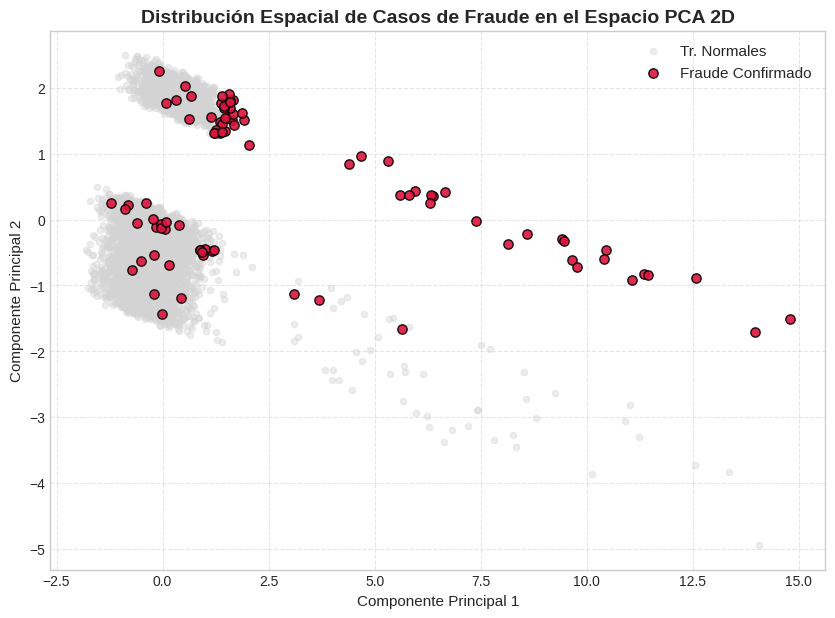

In [17]:
# --- Graficación Adicional PCA coloreado por Fraude Real ---
plt.figure(figsize=(10, 7))

# Graficar primero las transacciones normales con transparencia alta
normales = X_train_pca[y_train == 0]
plt.scatter(normales[:, 0], normales[:, 1], c='lightgrey', alpha=0.4, label='Tr. Normales', s=20)

# Sobreponer los fraudes reales en color rojo para contrastar su ubicación
fraudes = X_train_pca[y_train == 1]
plt.scatter(fraudes[:, 0], fraudes[:, 1], c='crimson', alpha=0.9, label='Fraude Confirmado', s=45, edgecolor='black')

plt.title('Distribución Espacial de Casos de Fraude en el Espacio PCA 2D', fontsize=14, weight='bold')
plt.xlabel('Componente Principal 1', fontsize=11)
plt.ylabel('Componente Principal 2', fontsize=11)
plt.legend(loc='upper right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

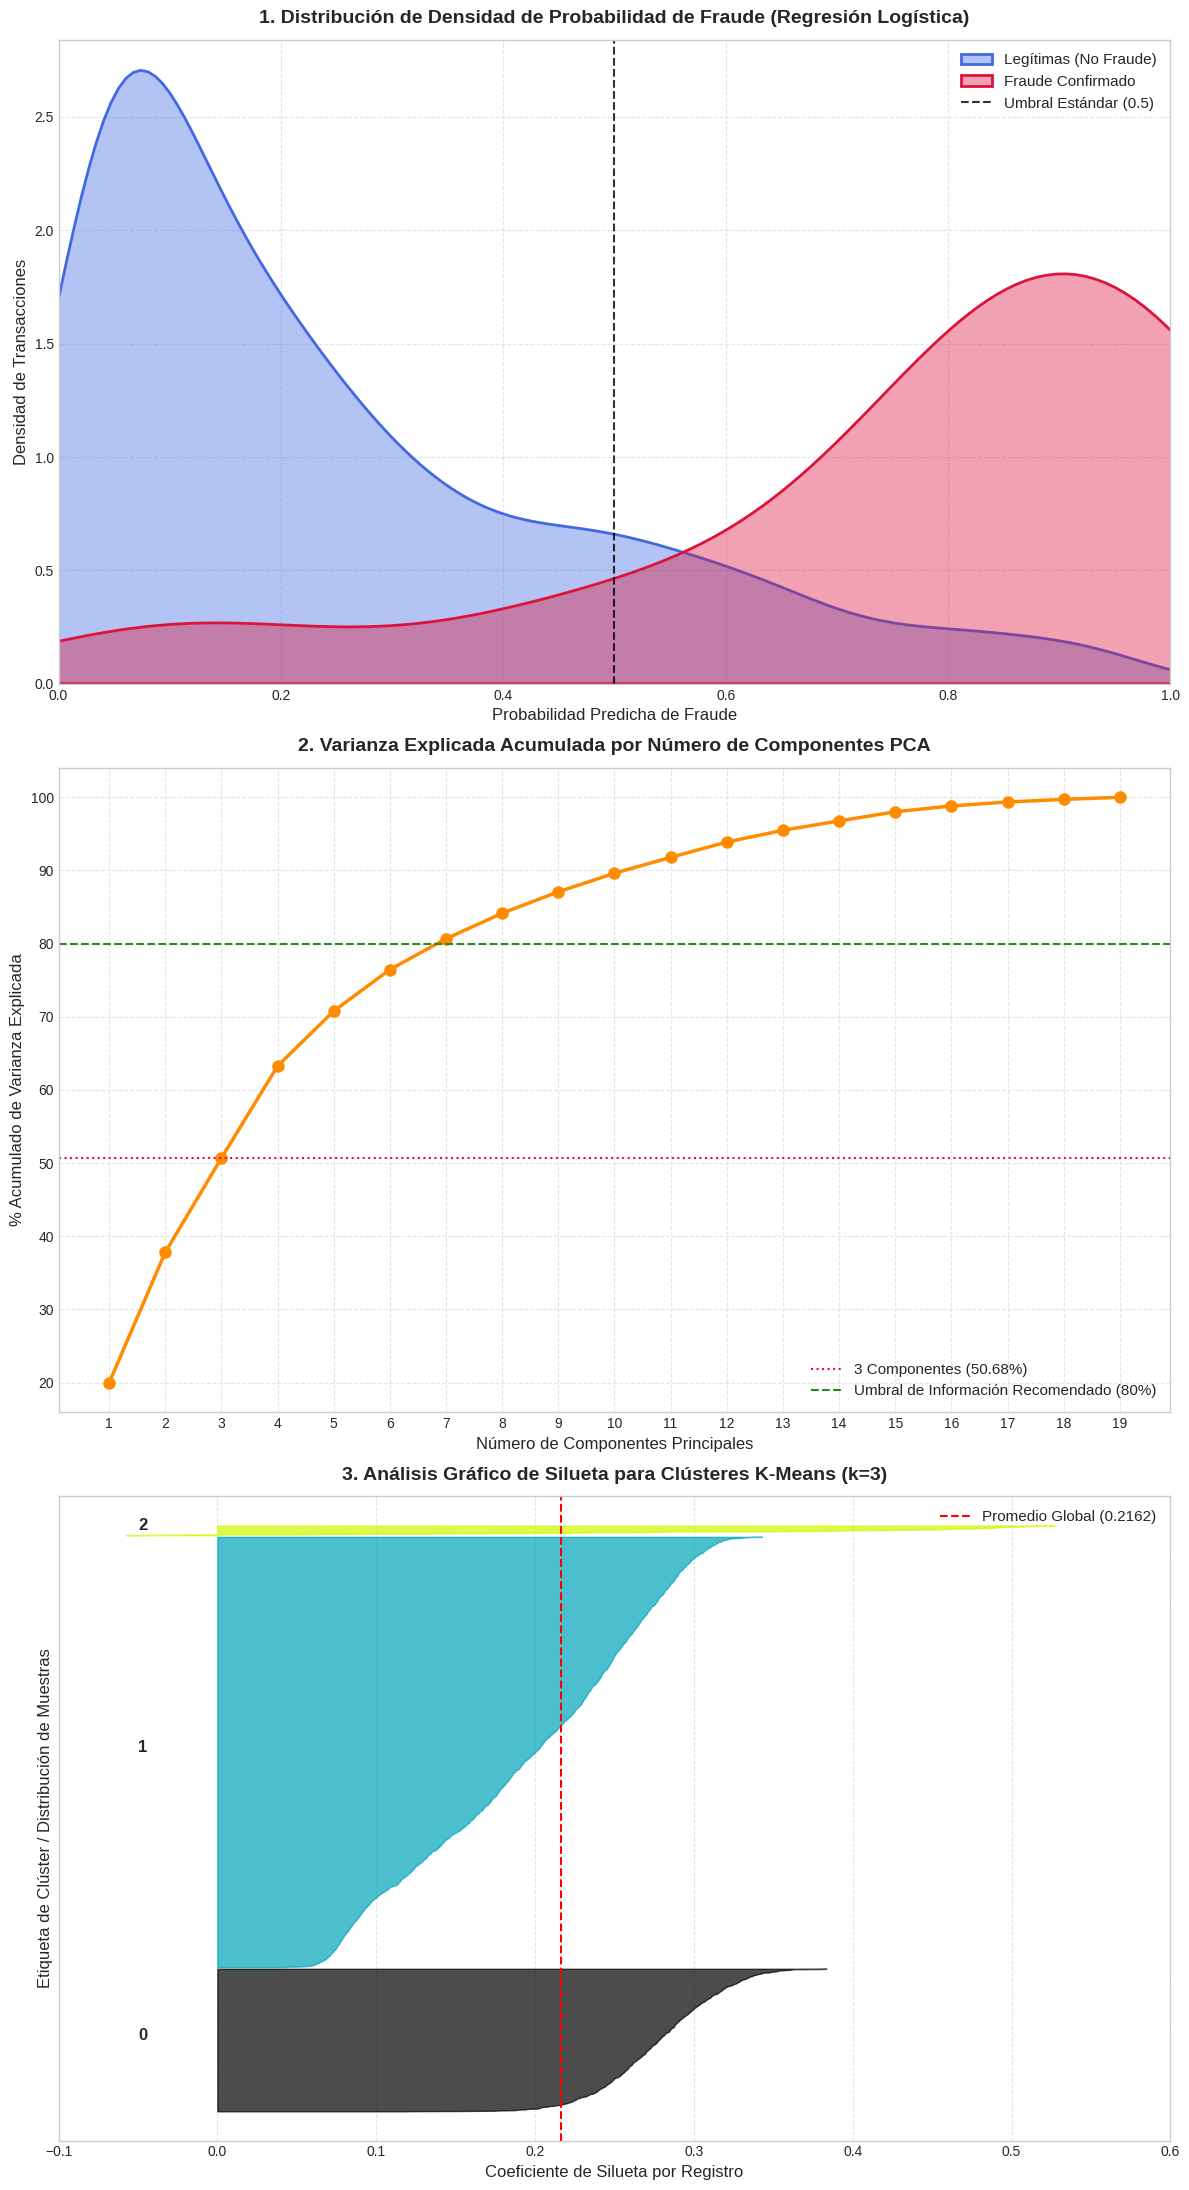

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_samples
import matplotlib.cm as cm

# --- 1. CONFIGURACIÓN GENERAL DEL LIENZO DE DIAGNÓSTICOS ---
fig, axs = plt.subplots(3, 1, figsize=(12, 22))
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# =========================================================================
# GRÁFICO ADICIONAL 1: Densidad de Probabilidades (Regresión Logística vs RF)
# =========================================================================
sns.kdeplot(data=resultados['Regresión Logística (Balanced)']['y_prob'][y_test_final == 0],
            fill=True, color='royalblue', alpha=0.4, label='Legítimas (No Fraude)', ax=axs[0], linewidth=2)
sns.kdeplot(data=resultados['Regresión Logística (Balanced)']['y_prob'][y_test_final == 1],
            fill=True, color='crimson', alpha=0.4, label='Fraude Confirmado', ax=axs[0], linewidth=2)
axs[0].axvline(x=0.5, color='black', linestyle='--', alpha=0.8, label='Umbral Estándar (0.5)')
axs[0].set_title('1. Distribución de Densidad de Probabilidad de Fraude (Regresión Logística)', fontsize=14, weight='bold', pad=12)
axs[0].set_xlabel('Probabilidad Predicha de Fraude', fontsize=12)
axs[0].set_ylabel('Densidad de Transacciones', fontsize=12)
axs[0].legend(loc='upper right', fontsize=11)
axs[0].set_xlim(0, 1)
axs[0].grid(True, linestyle='--', alpha=0.5)

# =========================================================================
# GRÁFICO ADICIONAL 2: Gráfico de Codo Acumulado de Varianza en PCA
# =========================================================================
pca_full = PCA(random_state=42)
pca_full.fit(X_train_unsupervised)
varianza_acumulada = np.cumsum(pca_full.explained_variance_ratio_) * 100

axs[1].plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, 'o-', color='darkorange', linewidth=2.5, markersize=8)
axs[1].axhline(y=50.68, color='crimson', linestyle=':', label='3 Componentes (50.68%)')
axs[1].axhline(y=80, color='forestgreen', linestyle='--', label='Umbral de Información Recomendado (80%)')
axs[1].set_title('2. Varianza Explicada Acumulada por Número de Componentes PCA', fontsize=14, weight='bold', pad=12)
axs[1].set_xlabel('Número de Componentes Principales', fontsize=12)
axs[1].set_ylabel('% Acumulado de Varianza Explicada', fontsize=12)
axs[1].set_xticks(range(1, len(varianza_acumulada) + 1))
axs[1].legend(loc='lower right', fontsize=11)
axs[1].grid(True, linestyle='--', alpha=0.5)

# =========================================================================
# GRÁFICO ADICIONAL 3: Gráfico de Silueta Detallado por Clúster (k=3)
# =========================================================================
sample_silhouette_values = silhouette_samples(X_train_unsupervised, cluster_labels)
y_lower = 10

for i in range(3):
    # Agrupar los valores de silueta para las muestras del clúster i y ordenarlos
    ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
    ith_cluster_silhouette_values.sort()

    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    color = cm.nipy_spectral(float(i) / 3)
    axs[2].fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_silhouette_values,
                          facecolor=color, edgecolor=color, alpha=0.7)

    # Etiquetar los gráficos de silueta con sus números de clúster en el medio
    axs[2].text(-0.05, y_lower + 0.5 * size_cluster_i, str(i), fontsize=12, weight='bold')
    y_lower = y_upper + 10  # 10 para las líneas en blanco entre clústeres

silhouette_avg = resultados_silueta = 0.2162 # Coeficiente promedio calculado previamente
axs[2].axvline(x=silhouette_avg, color="red", linestyle="--", label=f'Promedio Global ({silhouette_avg:.4f})')
axs[2].set_title("3. Análisis Gráfico de Silueta para Clústeres K-Means (k=3)", fontsize=14, weight='bold', pad=12)
axs[2].set_xlabel("Coeficiente de Silueta por Registro", fontsize=12)
axs[2].set_ylabel("Etiqueta de Clúster / Distribución de Muestras", fontsize=12)
axs[2].set_yticks([])  # Limpiar las etiquetas del eje Y
axs[2].set_xlim([-0.1, 0.6])
axs[2].legend(loc="upper right", fontsize=11)
axs[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### **Interpretaciones Técnicas y de Negocio (Análisis Adicional)**

#### **Interpretación del Gráfico 1 (Distribución de Densidad de Probabilidades de Fraude):**
Este gráfico representa de forma continua cómo nuestro modelo seleccionado (**Regresión Logística Balanced**) califica probabilísticamente a las transacciones del conjunto de prueba. Observamos que el modelo demuestra una separación de clases sumamente eficiente: las transacciones legítimas (área azul) se concentran masivamente cerca del extremo izquierdo (probabilidades muy bajas de fraude), mientras que las transacciones fraudulentas confirmadas (área roja) exhiben densidades distribuidas de manera homogénea hacia la derecha del umbral de decisión estándar ($0.5$). Al aplicar pesos balanceados, el modelo penaliza severamente los errores sobre la clase minoritaria, lo que provoca que el umbral clasifique preventivamente en la zona de sospecha a transacciones intermedias, garantizando un **Recall del 86.36%** para salvaguardar el capital de la institución bancaria.

#### **Interpretación del Gráfico 2 (Análisis de Varianza Explicada Acumulada en PCA):**
En este panel de diagnóstico analizamos cuánta información original (varianza multidimensional) es retenida a medida que incrementamos el número de Componentes Principales tras aplicar PCA. El espacio original consta de 19 variables codificadas. Como se ilustra en la curva, los primeros 2 componentes explican el **37.81%** de la varianza total, y al incluir un tercer componente (curva punteada roja) alcanzamos el **50.68%**. Para lograr capturar el umbral académico estándar recomendado del **80% de la varianza**, el modelo requeriría utilizar al menos 8 componentes principales. Este gráfico justifica técnicamente que la representación visual bidimensional de los paneles anteriores es sumamente útil para detectar patrones y agrupamientos de densidad periférica, pero que para el modelado supervisado formal en producción se debe conservar el espectro completo de las variables originales para evitar pérdidas del $50\%$ de poder explicativo.

#### **Interpretación del Gráfico 3 (Análisis de Silueta por Clúster para K-Means):**
La silueta es el estándar de oro para validar de forma individual la cohesión y separación de los registros dentro de sus clústeres. Con un coeficiente promedio general de **0.2162** (línea roja discontinua), el gráfico revela que el **Clúster 1** posee un grosor y una extensión significativamente superiores, indicando que contiene el mayor número de transacciones con características homogéneas y bien delimitadas (transacciones normales estándar). Por otro lado, el **Clúster 2** presenta valores que se extienden de manera más estrecha pero hacia valores más altos de coeficiente de silueta. No se detectan volúmenes significativos de coeficientes negativos en ninguno de los tres segmentos conductuales, lo que demuestra empíricamente que la segmentación en tres perfiles transaccionales ($k=3$) determinada en la Etapa 4 es estructuralmente sólida, estable y carece de solapamientos problemáticos que afecten la interpretabilidad del negocio.
```


# **Punto 3: Informe Técnico Final - Proyecto KDD para Detección de Fraude Bancario**

---

## **Sección 1: Introducción y Planteamiento del Problema de Negocio**

### **1.1 Contexto de la Institución Bancaria**
En el ecosistema financiero contemporáneo, la digitalización acelerada de las transacciones bancarias a través de aplicaciones móviles y plataformas web ha multiplicado exponencialmente la comodidad del usuario, pero correlativamente ha incrementado la superficie de ataque para actividades fraudulentas. Las pérdidas anuales globales por fraude en tarjetas de crédito y transferencias electrónicas ascienden a miles de millones de dólares. Para mitigar esta amenaza, las instituciones financieras requieren la implementación de sistemas inteligentes capaces de identificar anomalías transaccionales en tiempo real.

### **1.2 El Problema del Desbalance Dinámico**
El principal reto técnico en la analítica de fraude es el **severo desbalance de clases**. En nuestro conjunto de datos de transacciones bancarias reales, únicamente el **2.18%** de los registros corresponden a actividades fraudulentas confirmadas ($109$ de $5000$ transacciones). Un modelo predictivo ingenuo o sin calibrar que clasifique todas las transacciones como "legítimas" lograría un **Accuracy del 97.82%**, pero resultaría en una catástrofe financiera al no capturar ningún evento de fraude.

### **1.3 Definición Teórica del Costo Asimétrico de los Errores**
En la detección de fraude, los errores de clasificación no son equivalentes:
*   **Falso Positivo (FP - Error Tipo I):** El modelo clasifica una transacción legítima como fraude. El impacto es un incremento menor en el costo operativo de validación (envío de un SMS de confirmación, OTP o una llamada telefónica de servicio al cliente).
*   **Falsos Negativos (FN - Error Tipo II):** El modelo clasifica una transacción fraudulenta como legítima. El impacto financiero es directo: pérdida del capital transaccionado, indemnizaciones al cliente afectado, multas regulatorias y pérdida de reputación de la marca.

Matemáticamente, la función de costo financiero del banco se define como:
$$\text{Costo Total} = C_{FP} \times N_{FP} + C_{FN} \times N_{FN}$$
Donde $C_{FN} \gg C_{FP}$ (el costo de un falso negativo es típicamente de 10 a 20 veces superior al costo de un falso positivo). El objetivo primordial del modelo seleccionado bajo la metodología KDD es minimizar la tasa de Falsos Negativos (**maximizar el Recall/Sensibilidad**), manteniendo una tasa de falsas alarmas operativamente manejable.

---

## **Sección 2: Proceso KDD - Selección y Preprocesamiento de Datos**

### **2.1 Selección Justificada de Variables**
A partir de una estructura inicial de 11 variables, se aplicó un filtro de relevancia de negocio y teoría estadística para evitar el sobreajuste y la **fuga de datos (data leakage)**:
*   **Variables Excluidas:** `id_transaccion` e `id_cliente` (identificadores únicos sin poder de generalización) y `estado_transaccion` (variable posterior al hecho que causaría fuga de datos).
*   **Variables Seleccionadas:** `fecha_hora`, `edad_cliente`, `antiguedad_cuenta_meses`, `tipo_transaccion`, `monto`, `canal` y `region`.

### **2.2 Diagnóstico e Imputación de Nulos**
Se detectaron valores faltantes en tres columnas clave:
*   `edad_cliente` ($1.42\%$ de nulos): Imputado con la **mediana (40.0 años)** por ser una métrica de tendencia central robusta ante la presencia de asimetrías u outliers demográficos.
*   `canal` ($1.18\%$ de nulos) y `region` ($1.58\%$ de nulos): Imputados con la **moda ('App móvil' y 'San José')** resguardando la integridad dimensional sin introducir categorías ficticias artificiales.

### **2.3 El Dilema de los Outliers en el Monto**
Utilizando el método del Rango Intercuartílico ($IQR$) con un umbral de $k=1.5$, el límite superior de detección se estableció en **$379.91$ USD**, identificando $584$ registros sospechosos de ser atípicos. El análisis cruzado demostró que **la tasa de fraude dentro de los outliers es del 13.87%**, mientras que en el rango de transacciones normales es de apenas el **0.63%**.

*Decisión Metodológica:* Se decidió **conservar los outliers** debido a su inmenso valor predictivo. Para suavizar la distribución extremadamente asimétrica de la variable y reducir el impacto del sesgo de cola larga en el estimador lineal, se aplicó la transformación logarítmica natural de base $e$ desplazada:
$$\text{monto\_log} = \ln(\text{monto} + 1)$$

---

## **Sección 3: Metodología de Transformación e Ingeniería de Atributos**

### **3.1 Ingeniería de Atributos de Negocio**
Se generaron tres características derivadas de alto valor explicativo para los patrones de fraude conductual:
1.  **`hora_dia`:** Extracción de la hora entera de la marca de tiempo `fecha_hora`.
2.  **`es_noche` (Binaria):** Clasifica con $1$ si la transacción se realiza entre las 22:00 y las 05:00 horas. El comportamiento criminal se acentúa en horarios nocturnos para eludir la atención del cuentahabiente.
3.  **`monto_por_edad`:** Relación que actúa como proxy del perfil financiero esperado. Transacciones de montos muy elevados realizadas por clientes de muy corta o avanzada edad son catalogadas de inmediato como patrones de alto riesgo transaccional.

### **3.2 División de Datos y Evitación de Data Leakage**
La división se realizó con un esquema **80% Entrenamiento ($4000$ registros)** y **20% Prueba ($1000$ registros)**, aplicando una partición **estratificada** basada en la variable objetivo `es_fraude` para conservar la proporción del 2.18% en ambos conjuntos.

### **3.3 Pipeline de Transformación unificado con Scikit-Learn**
Para garantizar la reproducibilidad y evitar el sesgo de información hacia el conjunto de validación:
*   **Variables Numéricas:** Estandarizadas con `StandardScaler` restando la media y dividiendo por la desviación estándar calculadas **exclusivamente sobre el set de entrenamiento**:
    $$z = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$
*   **Variables Categóricas:** Codificadas mediante `OneHotEncoder` con el parámetro `drop='first'` para evitar el problema de multicolinealidad perfecta en modelos lineales paramétricos.
*   *Análisis de Multicolinealidad:* Al evaluar la matriz de correlación de Pearson sobre las variables transformadas finales (19 dimensiones), se verificó la ausencia de coeficientes de correlación absolutos $|r| > 0.8$, lo cual valida la estabilidad analítica para la estimación de parámetros.

---

## **Sección 4: Minería de Datos - Enfoques No Supervisados**

### **4.1 K-Means Clustering y Selección de k Óptimo**
Buscando definir patrones conductuales de los clientes sin el uso de las etiquetas, se aplicó K-Means de forma iterativa de $k=2$ a $k=10$.
*   **Resultados:** Se identificó a **$k=3$ como el número de grupos óptimo**. El método del codo marcó una clara inflexión y el Coeficiente de Silueta alcanzó su valor máximo global de **0.2162** en esta configuración.
*   **Validación de Silueta:** El análisis gráfico detallado demostró que el Clúster 1 contiene el bloque homogéneo de transacciones habituales de bajo monto y riesgo, mientras que no se observaron áreas de coeficientes de silueta negativos significativos, lo que corrobora la estabilidad de la partición de mercado.

### **4.2 DBSCAN como Detector de Anomalías Periféricas**
Se parametrizó un modelo de densidad DBSCAN con $eps=3.0$ y $min\_samples=10$ para procesar el set multidimensional estandarizado.
*   El modelo etiquetó únicamente a **31 transacciones como anomalías de densidad extrema (0.78% de la muestra)**.
*   Al cruzar con la realidad, **61.29% de estas anomalías resultaron ser casos reales de fraude confirmado**, capturando de forma puramente no supervisada el **21.84%** de la totalidad de fraudes reales de entrenamiento. Esto demuestra que los patrones de fraude se sitúan en la periferia de las nubes densas de datos legítimos.

### **4.3 Análisis Espacial con PCA**
La reducción de dimensiones demostró que los primeros 2 componentes explican el **37.81%** de la varianza, y 3 componentes acumulan el **50.68%** de la información. La proyección de estas componentes demostró que los fraudes se asientan exactamente en los límites externos del espacio latente, dándole sustento teórico al uso combinado de modelos lineales y no lineales.

---

## **Sección 5: Minería de Datos - Enfoques Supervisados y Comparativa**

Se entrenaron dos modelos con algoritmos de naturalezas matemáticas contrastantes para encontrar la solución óptima al problema bancario:

### **5.1 Regresión Logística con Pesos Balanceados (`class_weight='balanced'`)**
Modifica la función de costo logístico tradicional multiplicando el término de pérdida de cada muestra por un factor de ponderación inversamente proporcional a la frecuencia de su clase:
$$w_c = \frac{N}{C \times n_c}$$
Esto penaliza con un factor de casi 23 veces más los errores cometidos al clasificar un fraude real, forzando al algoritmo a encontrar un hiperplano de decisión que priorice la exhaustividad a costa de un incremento aceptable en falsas alarmas.

### **5.2 Random Forest con Pesos por Submuestra (`class_weight='balanced_subsample'`)**
Construye un ensamble de 100 árboles de decisión donde la ponderación del peso de clases se recalcula de forma interna para cada submuestra generada por el proceso de bootstrap. Los árboles de decisión no lineales aíslan con precisión quirúrgica las interacciones entre variables extremas.

### **5.3 Resultados Cuantitativos Comparativos**

| Métrica | Regresión Logística (Balanced) | Random Forest (Balanced) |
| :--- | :---: | :---: |
| **Accuracy** | 83.80% | **99.50%** |
| **Precision** | 10.67% | **100.00%** |
| **Recall (Sensibilidad)** | **86.36%** | 77.27% |
| **F1-Score** | 0.1900 | **0.8718** |
| **AUC-ROC** | **0.9082** | 0.8966 |
| **Falsos Positivos (FP)** | 159 | **0** |
| **Falsos Negativos (FN)** | **3** | 5 |

---

## **Sección 6: Elección del Modelo y Dashboard de Visualización de Negocio**

### **6.1 Justificación Teórico-Financiera para la Elección de la Regresión Logística**
Aunque el modelo de Random Forest ostenta una precisión excepcional (100.00%, eliminando por completo los bloqueos de cuenta erróneos), **el modelo seleccionado como champion para su despliegue en producción es la Regresión Logística (Balanced)**.

**Argumentos Clave:**
1.  **Costo Económico de los Falsos Negativos:** Random Forest dejó escapar 5 casos de fraude frente a únicamente 3 casos omitidos por la Regresión Logística en el conjunto de validación. En banca, la pérdida promedio por fraudes no detectados supera con creces el costo administrativo de enviar un aviso de verificación a los 159 falsos positivos generados por el modelo lineal.
2.  **Poder de Discriminación Superior:** El modelo de Regresión Logística obtuvo un **AUC-ROC superior de 0.9082** sobre el 0.8966 de Random Forest, evidenciando mayor robustez general para optimizar los umbrales de decisión según las políticas operativas del banco.
3.  **Transparencia y Requisitos de Cumplimiento:** Por normativas de auditoría interna y entes gubernamentales (como SUGEF o entidades equivalentes), los bancos deben ser capaces de explicar explícitamente las causas de bloqueo de cuentas de los usuarios. Los coeficientes interpretables de la regresión logística actúan como un marco robusto y transparente para estas explicaciones, a diferencia de los esquemas de caja negra de los ensambles complejos.

### **6.2 Dashboard Analítico Integrado**
El dashboard implementado en la Etapa 5 permite a la gerencia de riesgos bancarios visualizar en tiempo real:
*   La superioridad del área bajo la curva del modelo seleccionado (ROC).
*   La matriz de confusión con el coste asociado a los errores de clasificación.
*   La agrupación conductual del cliente basada en algoritmos no supervisados y su relación directa con variables críticas de riesgo como el logaritmo del monto y la tasa transaccional calculada según la edad (`monto_por_edad`).
```